In [ ]:
pip install numpy gymnasium stable-baselines3 sb3-contrib

In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.monitor import Monitor


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [2]:
пять стаканов с разным количеством жидкости. Нужно добиться того, чтобы во всех стаканах объём стал одинаковым, переливая жидкость из переполненных стаканов в недолившиеся.
агент пробует действия, наблюдает результат и получает награду или штраф.

1) Агент   кто принимает решения в данном слкучае модель PPO.
2) Среда   Правила задачи и состояние стаканов GlassesEnv
3) Награда Числовая оценка результата действия

4) Наблюдение Информация, которую среда передаёт агенту (массив объёмов жидкости)
5) Действие   выбор одного из n стаканов

Политика правило, по которому агент выбирает действия в зависимости от наблюдения.
Эпизод одна попытка решить задачу (от создания начальных объёмов до успеха или окончания лимита шагов)

SyntaxError: invalid syntax (2844242754.py, line 1)

1 шаг RL выглядит так
- Среда выдаёт состояние (обьемы стаканов)
- PPO выбирает действие (выбрать стакан)
- Среда выполянет дейтсиве  (в нашемм проекте step)
- Среда получает результат (Новое состояние, reward, признак завершения)
- Сохраняем цепочку действий с результатами и далее PPO обновляет сеть

Мы написали среду (условия задачи) в которой PPO обучается


In [1]:
Цель RL-алгоритма (обучение с подкрепление) заключается в максимизации выгод за заданный период времени.

SyntaxError: invalid syntax (1084134954.py, line 1)

У нас ессть 5 стаканов
что бы алгоритмически эффективно перелить нужно

PPO не минимизирует error() напрямую. Алгоритм получает reward, который зависит от изменения ошибки после действия.
Рассмотрим три ситуации.

1. Агент уменьшил ошибку
Было 0.4, стало 0.2.
r=-1+2(0.4-0.2)=-0.6
Награда отрицательная, но действие оказалось полезным: агент получил больше, чем получил бы при отсутствии прогресса, когда reward равен -1.


2. Агент ничего не изменил
Было 0.4, осталось 0.4.
r=-1+2(0.4-0.4)=-1
Агент получает штраф за потраченный шаг.


3. Агент выровнял стаканы
Если после действия ошибка стала нулевой и выполнено условие is_success():
r=-1+2(0.4-0)+10=9.8
Агент получает большой бонус за завершение задачи.

In [ ]:
class GlassesEnv(gym.Env):
  """Выровниваем объемы жидкости в N стаканах, сделав как можно меньше переливаний.

    Начальные объемы выбираются независимо
    из диапазона [0, 1]. Целевой показатель среднее значение начальных объемов, которое остается неизменным на протяжении всего процесса.
    """
    metadata = {"render_modes": []}

    def __init__(self, n, max_steps=None):
        super().__init__()
        self.n = n                    # кол-во стаканов
        self.capacity = 1.0           # максимальный обьем стакана
        self.max_steps = max_steps if max_steps is not None else 3 * n
                                      # максимальной количесвто действий
        self.tol = 1e-5               # допустимое отклоннение от цели.

        self.action_space = spaces.Discrete(n) # доступные действия 5 штук (выбрать стакан)
        self.observation_space = spaces.Box( # какие наблюдения получает агенn
            low=0.0,
            high=self.capacity,
            shape=(n,),
            dtype=np.float32,
        )

        self.volumes = np.zeros(n, dtype=np.float64)
        self.target = 0.0
        self.initial_total = 0.0
        self.steps = 0

    def target_level(self):
        return self.target

    def error(self):
        # считаем отклонения от целевого уровне в abs,
        # так если в одном стакане 0,8 и во втором 0,2 аа цельт 0.5 отклонения между обьемами будет 0.6 а преелить нужно всего 0.3, поэтому делим отклоеняи на 2
        return float(0.5 * np.abs(self.volumes - self.target).sum())

    def is_success(self):
        # Каждый стакан должен находиться в пределах допустимого отклонения от целевого уровня.
        return bool(np.all(np.abs(self.volumes - self.target) <= self.tol))

    def reset(self, seed=None): # новый эпизод
        super().reset(seed=seed)

        # каждый обьем распределяем от 0 до 1 на стакан n штук создаем
        self.volumes = self.np_random.uniform(
            0.0, self.capacity, size=self.n
        ).astype(np.float64)

        self.initial_total = float(self.volumes.sum())
        # по сути средний обььем по всем 5 стаканм = это наш целевой уровень (состояние равенства) фиксируем
        # не надо после каждого шага пресчитывать т.к. целевой уровень для эпизода не меняется
        self.target = self.initial_total / self.n
        self.steps = 0 # обнулилли счетчик действий


        return self.volumes.astype(np.float32), {
            "target": self.target,
            "total_volume": self.initial_total,
        }

    # !!!!!!! важно
    def step(self, action):
        # среда принимает выбранный агентом индекс стакана (action) и проверяет, сколько в нём жидкости сверх целевого уровня excess.
        self.steps += 1
        error_before = self.error()
        i = int(action)
        excess = self.volumes[i] - self.target

        if excess > self.tol:
            # Среда рассчитывает, сколько жидкости не хватает остальным стаканам.
            # ставим 0 для переполненных стаканов (сврех цели где налито)
            deficits = np.maximum(self.target - self.volumes, 0.0)
            deficits[i] = 0.0 # исключает выбранный стакан из получателей жидкости.
            total_deficit = float(deficits.sum())

            if total_deficit > self.tol:
                transfer = excess * deficits / total_deficit
                #Каждый недолившийся стакан получает долю пропорционально тому, сколько ему не хватает.
                # это легче чем доливать до целевого обьема не равными частями хотя не очень очевидно
                self.volumes[i] = self.target
                self.volumes += transfer
        # Среда повторно вычисляет ошибку и проверяет, достигнута ли цель.
        error_after = self.error()
        success = self.is_success()

        # награда поощряет уменьшение ошибки, штрафует за каждый шаг и добавляет бонус за успех.
        # агент поднял переполненный стакан и ошибка уменьшилась с 0.3 до 0.1. награда -1 + 2(0.3-0.1) = -0.6
        # поднял недолитый стакан -1
        # все стаканы выровнены, добавляется бонус +10
        reward = -1.0 + 2.0 * (error_before - error_after)
        if success:
            reward += 10.0

        truncated = self.steps >= self.max_steps and not success
        info = {
            "error": error_after,
            "target": self.target,
            "total_volume": float(self.volumes.sum()),
            "lifts": self.steps,
        }
        #пять значений, которые ожидает Gymnasium:
        return (
            self.volumes.astype(np.float32), #новое состояние
            float(reward),                   #награда за действие
            success,                         # завершилась ли задача естественным образом
            truncated,                       #закончился ли лимит шагов без успеха
            info,                            #доп данные
        )



In [ ]:

class RewardPlotCallback(BaseCallback):
   """Собирает данные о возвращенных эпизодах с Monitor и строит график кривой обучения»."""

    def __init__(self, verbose=0):
        super().__init__(verbose)
        self.episode_rewards = []

    def _on_step(self) -> bool:
        for info in self.locals.get("infos", []):
            if "episode" in info:
                self.episode_rewards.append(float(info["episode"]["r"]))
        return True

    def plot(self, window=50, save_path="glasses_learning_curve.png"):
        rewards = np.asarray(self.episode_rewards, dtype=np.float64)
        if rewards.size == 0:
            print("Нет завершённых эпизодов для построения графика.")
            return

        window = max(1, min(int(window), len(rewards)))
        episodes = np.arange(1, len(rewards) + 1)

        plt.figure(figsize=(12, 5))
        plt.plot(episodes, rewards, alpha=0.3, label="Награда за эпизод")

        moving_avg = np.convolve(
            rewards, np.ones(window) / window, mode="valid"
        )
        plt.plot(
            np.arange(window, len(rewards) + 1),
            moving_avg,
            linewidth=2,
            label=f"Скользящее среднее ({window} эпизодов)",
        )
        plt.xlabel("Номер завершённого эпизода")
        plt.ylabel("Суммарная награда")
        plt.title("Кривая обучения PPO для GlassesEnv")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.savefig(save_path, dpi=160, bbox_inches="tight")
        plt.show()
        print(f"График сохранён в: {save_path}")

Using cuda device
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 8        |
|    ep_rew_mean     | 1.74     |
| time/              |          |
|    fps             | 370      |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 512      |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 8.59        |
|    ep_rew_mean          | 1.38        |
| time/                   |             |
|    fps                  | 327         |
|    iterations           | 2           |
|    time_elapsed         | 3           |
|    total_timesteps      | 1024        |
| train/                  |             |
|    approx_kl            | 0.006756893 |
|    clip_fraction        | 0.00508     |
|    clip_range           | 0.2         |
|    entropy_loss         | -1.61       |
|    explained_variance   | 0.00288     |
|    learning_rate        | 0.

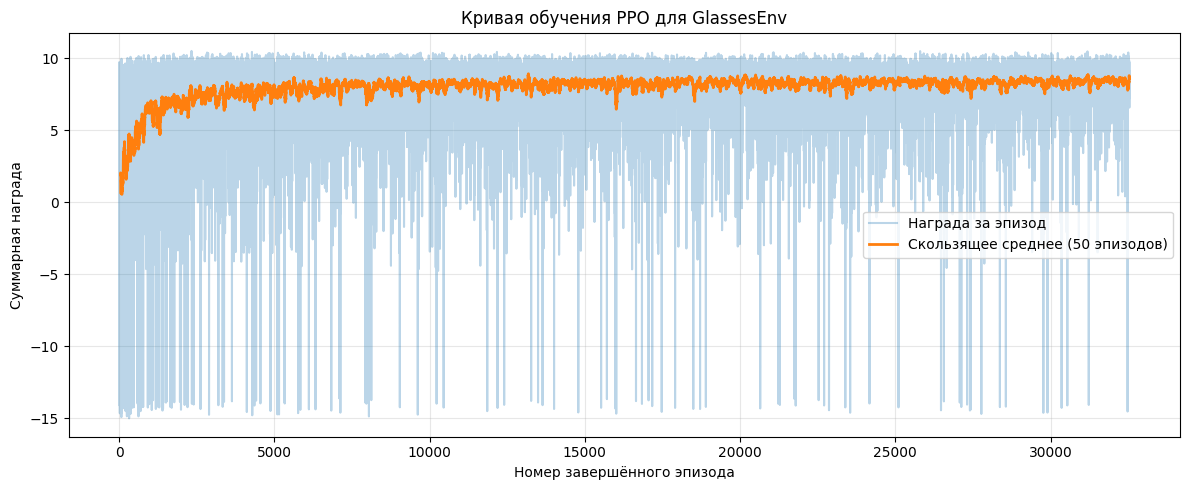

График сохранён в: glasses_learning_curve.png

Исходные объёмы: [0.774 0.439 0.859 0.697 0.094]
Целевой уровень: 0.573
Теоретический минимум подъёмов: 3

Подняли стакан №1 | объёмы: [0.573 0.483 0.859 0.697 0.252] | награда: -0.597
Подняли стакан №3 | объёмы: [0.573 0.545 0.573 0.697 0.475] | награда: -0.428
Подняли стакан №4 | объёмы: [0.573 0.573 0.573 0.573 0.573] | награда: 9.250

Успех! Все уровни выровнены.
Фактические подъёмы: 3
Финальные объёмы: [0.573 0.573 0.573 0.573 0.573]
Финальная ошибка: 1.6653345369377348e-16


In [ ]:



if __name__ == "__main__":
    N = 5
    # DQN  можно попробовать так же
    # пользовательская среда Gymnasium перед обучением
    check_env(GlassesEnv(n=N), warn=True)
    env = Monitor(GlassesEnv(n=N))
    reward_callback = RewardPlotCallback()
                  # stable-baselines3 готовые реализации PPO и других алгоритмов RL.
    model = PPO( # Proximal Policy Optimization метод оптимизации политики с ограничением величины её обновлений.
        "MlpPolicy", # многослойная полносвязная нейросеть. (перцепртон)
        env,    # отдаем ссреду в PPO
        learning_rate=3e-4,
        n_steps=512,
        batch_size=64,
        gamma=0.99,
        verbose=1,
    )
    model.learn(total_timesteps=100_000, callback=reward_callback)
    # тут внутри вызывается reset потом step (). когда накопили 512 шагов обновляем
    model.save(f"ppo_glasses_{N}")
    reward_callback.plot(window=50)

    # оценка воспроизводимая
    test_env = GlassesEnv(n=N)
    obs, _ = test_env.reset(seed=42)
    start_volumes = test_env.volumes.copy()  #
    target = test_env.target_level()          # цели для этого эпизода

    optimal_lifts = int(
        np.count_nonzero(start_volumes > target + test_env.tol)
    )

    print("\nИсходные объёмы:", np.round(start_volumes, 3))
    print("Целевой уровень:", round(target, 3))
    print("Теоретический минимум подъёмов:", optimal_lifts)
    print()

    terminated = test_env.is_success()
    truncated = False
    # iterations  номер цикла обучения PPO
    # timestep 1 шаг в среде (поднятие).
    while not (terminated or truncated):
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = test_env.step(action)
        print(
            f"Подняли стакан №{int(action) + 1} | "
            f"объёмы: {np.round(obs, 3)} | "
            f"награда: {reward:.3f}"
        )

    print()
    if terminated:
        print("Успех! Все уровни выровнены.")
    else:
        print("Лимит действий достигнут. Эпизод не решён.")

    print("Фактические подъёмы:", test_env.steps)
    print("Финальные объёмы:", np.round(test_env.volumes, 3))
    print("Финальная ошибка:", test_env.error())


In [ ]:
    test_env = GlassesEnv(n=N)
    obs, _ = test_env.reset(seed=362)
    start_volumes = test_env.volumes.copy()
    target = test_env.target_level()

    optimal_lifts = int(
        np.count_nonzero(start_volumes > target + test_env.tol)
    )

    print("\nИсходные объёмы:", np.round(start_volumes, 3))
    print("Целевой уровень:", round(target, 3))
    print("Теоретический минимум подъёмов:", optimal_lifts)
    print()

    terminated = test_env.is_success()
    truncated = False

    while not (terminated or truncated):
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = test_env.step(action)
        print(
            f"Подняли стакан №{int(action) + 1} | "
            f"объёмы: {np.round(obs, 3)} | "
            f"награда: {reward:.3f}"
        )

    print()
    if terminated:
        print("Успех! Все уровни выровнены.")
    else:
        print("Лимит действий достигнут. Эпизод не решён.")

    print("Фактические подъёмы:", test_env.steps)
    print("Финальные объёмы:", np.round(test_env.volumes, 3))
    print("Финальная ошибка:", test_env.error())



Исходные объёмы: [0.141 0.594 0.211 0.088 0.5  ]
Целевой уровень: 0.307
Теоретический минимум подъёмов: 2

Подняли стакан №2 | объёмы: [0.24  0.307 0.268 0.219 0.5  ] | награда: -0.426
Подняли стакан №5 | объёмы: [0.307 0.307 0.307 0.307 0.307] | награда: 9.387

Успех! Все уровни выровнены.
Фактические подъёмы: 2
Финальные объёмы: [0.307 0.307 0.307 0.307 0.307]
Финальная ошибка: 5.551115123125783e-17
